In [2]:
# Step 1: Import libraries
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

In [3]:
# Step 2: Load datasets
train_data = pd.read_csv('sign_mnist_train.csv')
test_data = pd.read_csv('sign_mnist_test.csv')
print("Training Data:", train_data.shape)
print("Testing Data:", test_data.shape)

Training Data: (27455, 785)
Testing Data: (7172, 785)


In [4]:
# Step 3: Separate features and labels
X_train = train_data.drop('label', axis=1).values
y_train = train_data['label'].values

X_test = test_data.drop('label', axis=1).values
y_test = test_data['label'].values

In [5]:
# Step 4: Convert labels into 24 consecutive classes
classes = np.sort(np.unique(y_train))
label_map = {label: i for i, label in enumerate(classes)}

y_train = np.array([label_map[x] for x in y_train])
y_test = np.array([label_map[x] for x in y_test])


In [6]:
# Step 5: Normalize pixel values
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

In [7]:
# Step 6: Flatten images
X_train = X_train.reshape(-1, 784)
X_test = X_test.reshape(-1, 784)


In [8]:
# Step 7: Split training data for validation
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)


In [9]:
# Step 8: Build FNN with TWO hidden Dense layers
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(784,)),

    # First hidden layer
    tf.keras.layers.Dense(128, activation='relu'),

    # Second hidden layer
    tf.keras.layers.Dense(64, activation='relu'),

    # Output layer
    tf.keras.layers.Dense(24, activation='softmax')
])


In [10]:
# Step 9: Compile the model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [11]:
# Step 10: Display model summary
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 24)             │         1,560 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,296 (430.84 KB)

 Trainable params: 110,296 (430.84 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
# Step 11: Train the model
history = model.fit(
    X_train, y_train,
    epochs=15,
    batch_size=128,
    validation_data=(X_val, y_val)
)

Epoch 1/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.2311 - loss: 2.6228 - val_accuracy: 0.4105 - val_loss: 1.9957
Epoch 2/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.4777 - loss: 1.7209 - val_accuracy: 0.5606 - val_loss: 1.4843
Epoch 3/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.5981 - loss: 1.3362 - val_accuracy: 0.6123 - val_loss: 1.2339
Epoch 4/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.6684 - loss: 1.1042 - val_accuracy: 0.6869 - val_loss: 1.0268
Epoch 5/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.7151 - loss: 0.9518 - val_accuracy: 0.7447 - val_loss: 0.8891
Epoch 6/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.7567 - loss: 0.8269 - val_accuracy: 0.7516 - val_loss: 0.8156
Epoch 7/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.7877 - loss: 0.7336 - val_accuracy: 0.8039 - val_loss: 0.7024
Epoch 8/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8122 - loss: 0.6402 - val_accuracy:

In [14]:
# Step 12: Evaluate model
test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("\nTraining Accuracy: {:.2f}%".format(
    history.history['accuracy'][-1] * 100
))

print("Testing Accuracy: {:.2f}%".format(
    test_accuracy * 100
))

print("Testing Loss:", test_loss)

225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6907 - loss: 1.1412

Training Accuracy: 93.42%
Testing Accuracy: 69.07%
Testing Loss: 1.141157865524292


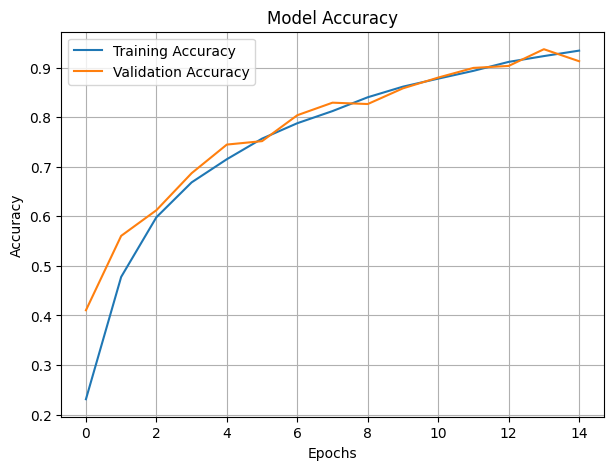

In [15]:
# Step 13: Display accuracy graph
plt.figure(figsize=(7, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

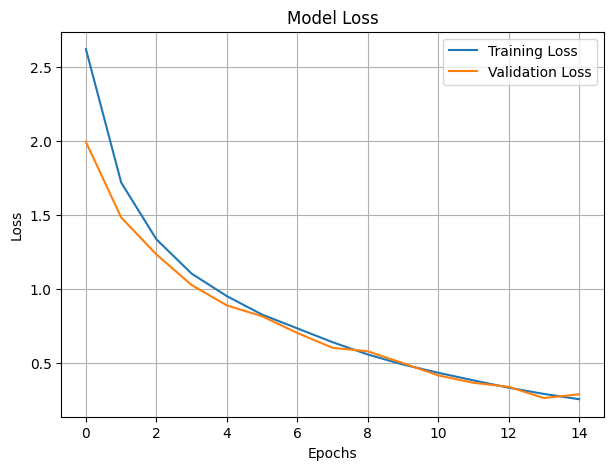

In [16]:
# Step 14: Display loss graph
plt.figure(figsize=(7, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step


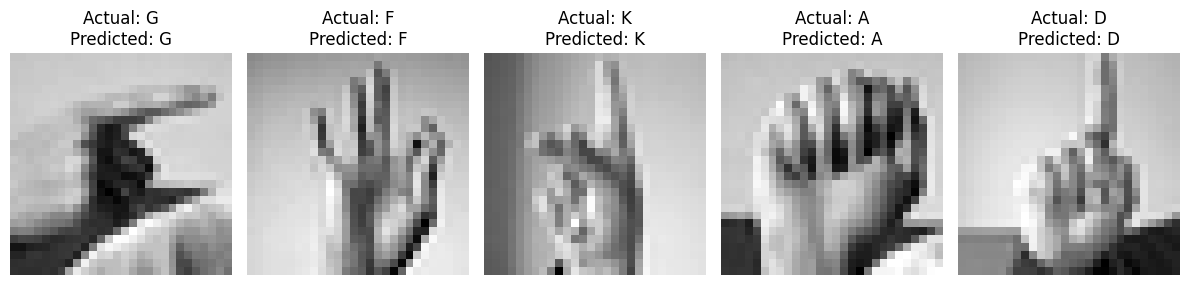

In [17]:
# Step 15: Observe performance on sample test images
predictions = model.predict(X_test[:5])

predicted_labels = np.argmax(predictions, axis=1)

# Convert labels into alphabet letters
actual_letters = [chr(classes[label] + 65) for label in y_test[:5]]
predicted_letters = [
    chr(classes[label] + 65) for label in predicted_labels
]

plt.figure(figsize=(12, 5))

for i in range(5):
    plt.subplot(1, 5, i + 1)

    plt.imshow(X_test[i].reshape(28, 28), cmap='gray')

    plt.title(
        f"Actual: {actual_letters[i]}\n"
        f"Predicted: {predicted_letters[i]}"
    )

    plt.axis('off')

plt.tight_layout()
plt.show()


In [ ]:
# Implement a Feedforward Neural Network for Sign Language recognition
# using two hidden Dense layers. Train the model and display its accuracy
# and loss. Also, observe the model's performance on sample test images.